Dataset shape: (1050, 11)

First 5 rows:
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  \
0   0.496714  -0.138264   0.647689   1.523030  -0.234153  -0.234137   
1  -0.463418  -0.465730   0.241962  -1.913280  -1.724918  -0.562288   
2   1.465649  -0.225776   0.067528  -1.424748  -0.544383   0.110923   
3  -0.601707   1.852278  -0.013497  -1.057711   0.822545  -1.220844   
4   0.738467   0.171368  -0.115648  -0.301104  -1.478522  -0.719844   

   Feature_7  Feature_8  Feature_9  Feature_10  IsAnomaly  
0   1.579213   0.767435  -0.469474    0.542560          0  
1  -1.012831   0.314247  -0.908024   -1.412304          0  
2  -1.150994   0.375698  -0.600639   -0.291694          0  
3   0.208864  -1.959670  -1.328186    0.196861          0  
4  -0.460639   1.057122   0.343618   -1.763040          0  

Scaled data shape: (1050, 10)


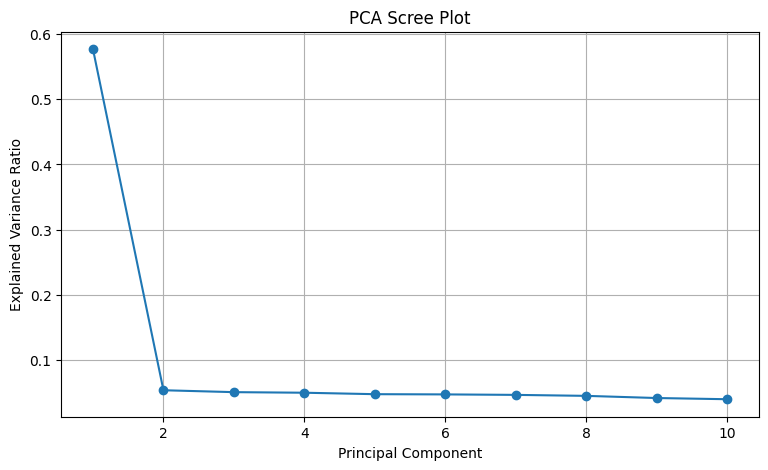

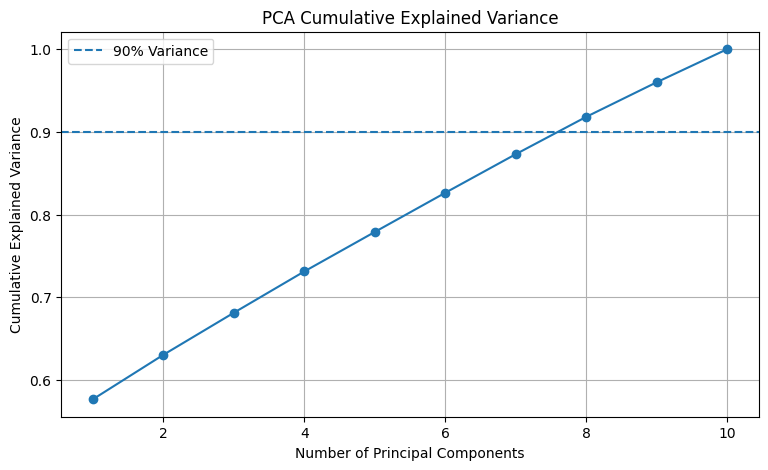

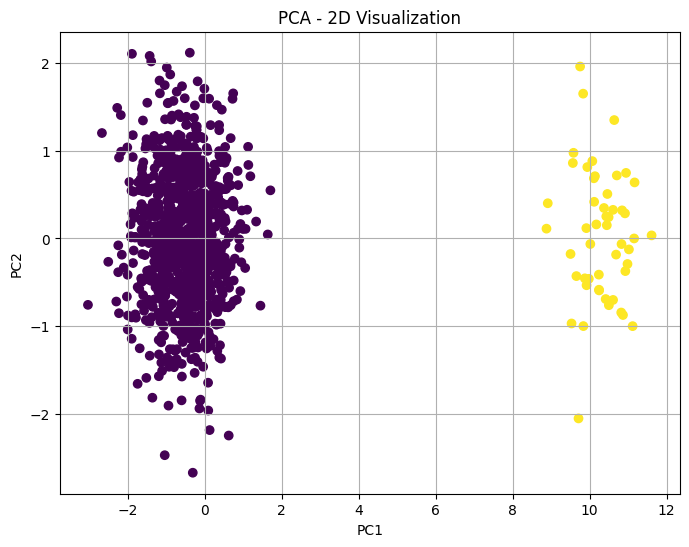

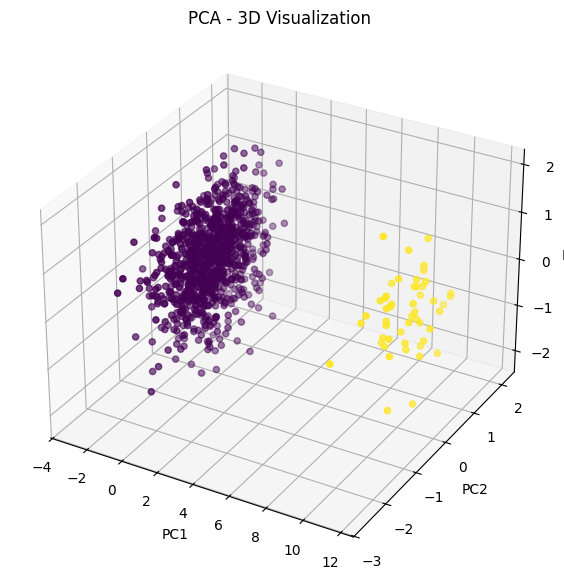

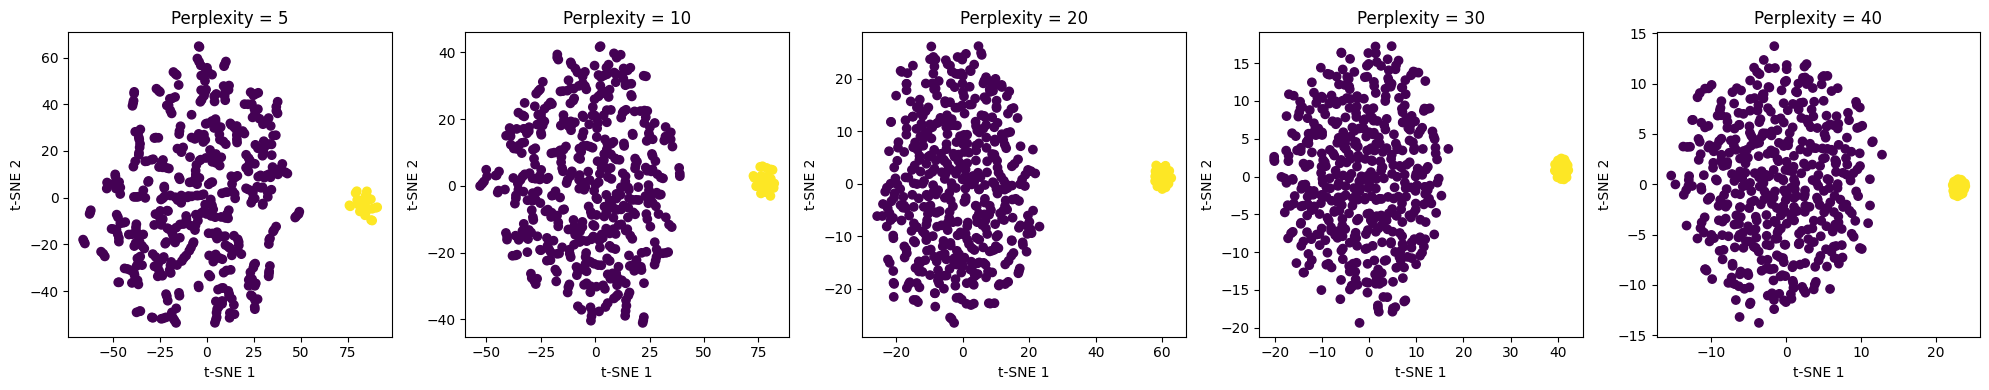

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

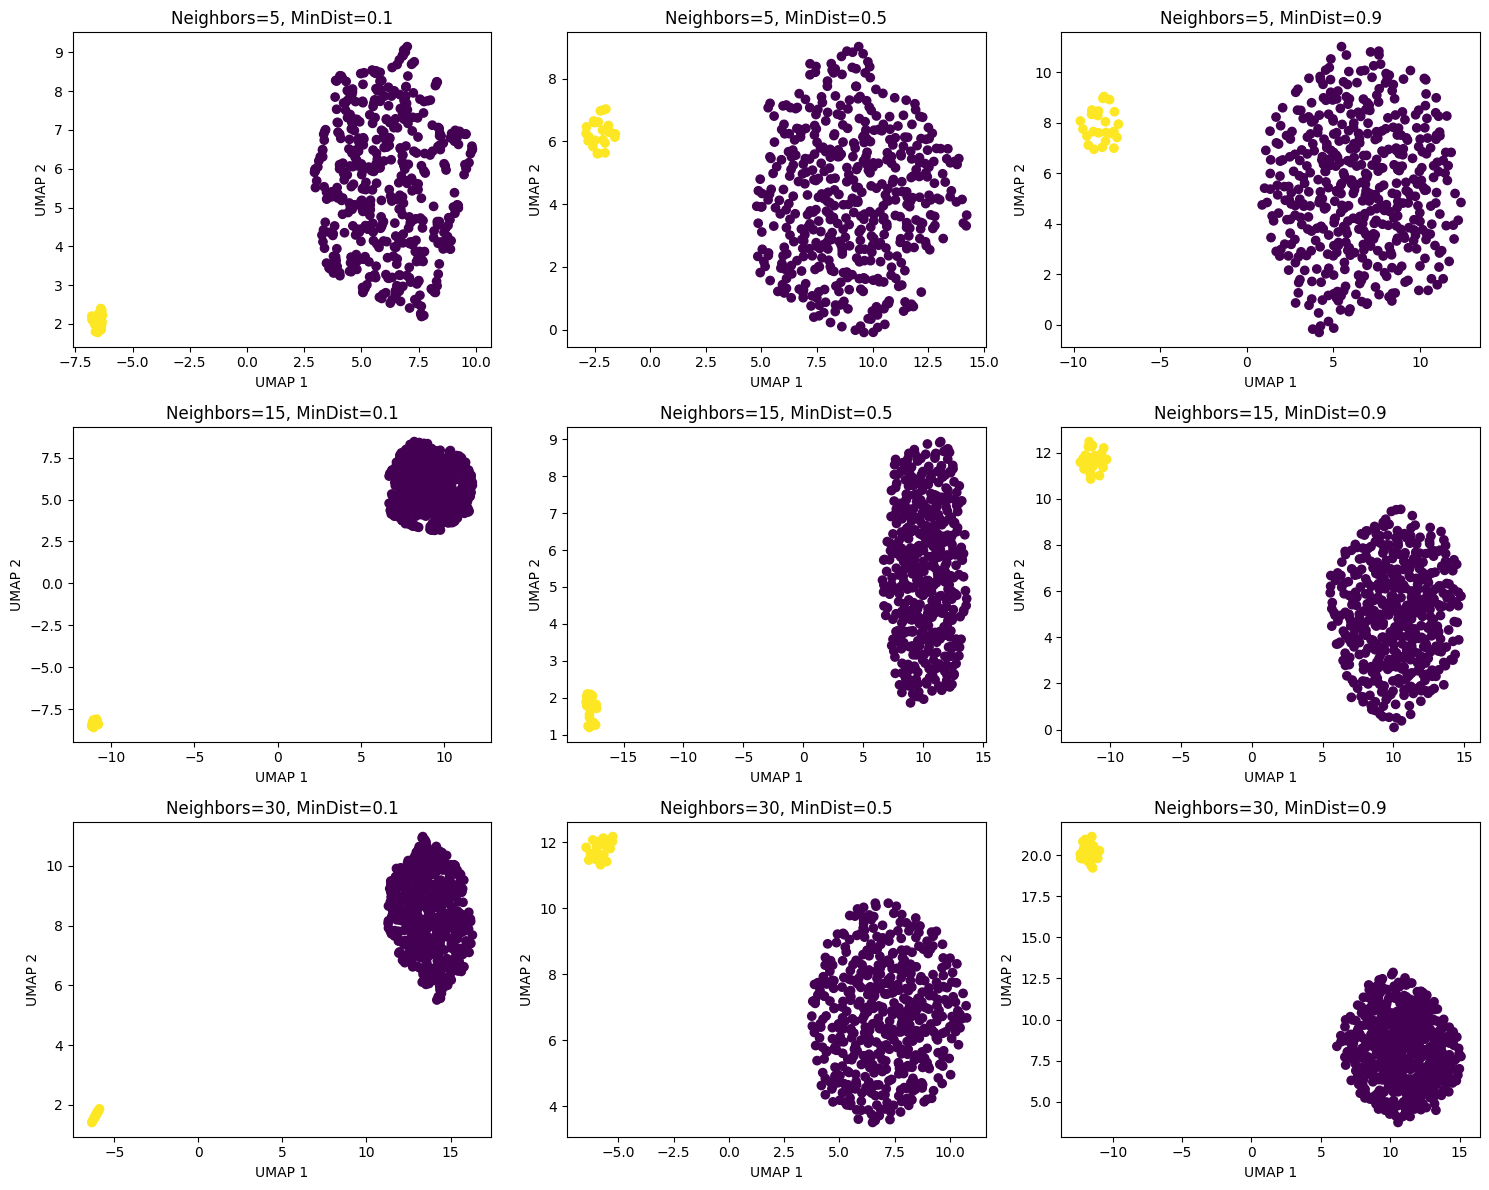


ISOLATION FOREST VS GROUND TRUTH

Accuracy: 1.0

Confusion Matrix:
[[1000    0]
 [   0   50]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      1000
     Anomaly       1.00      1.00      1.00        50

    accuracy                           1.00      1050
   macro avg       1.00      1.00      1.00      1050
weighted avg       1.00      1.00      1.00      1050


Comparison Table:
    GroundTruth_IsAnomaly  IsolationForest_IsAnomaly
0                       0                          0
1                       0                          0
2                       0                          0
3                       0                          0
4                       0                          0
5                       0                          0
6                       0                          0
7                       0                          0
8                       0                          0
9    

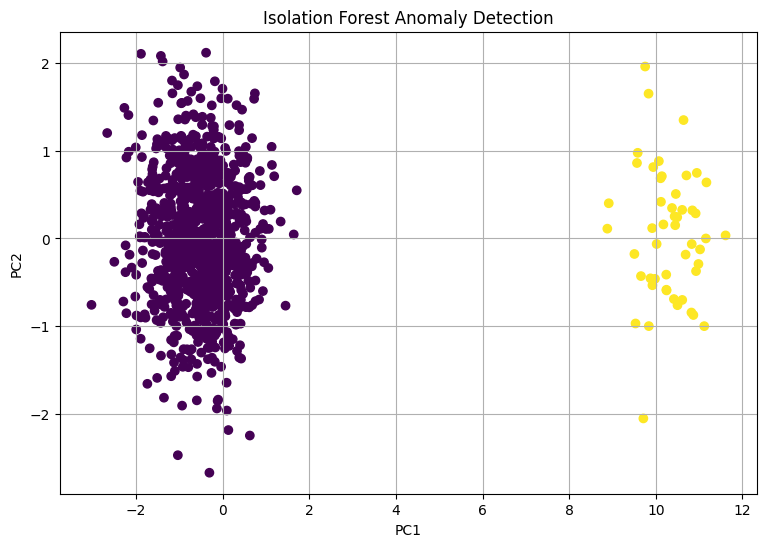

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


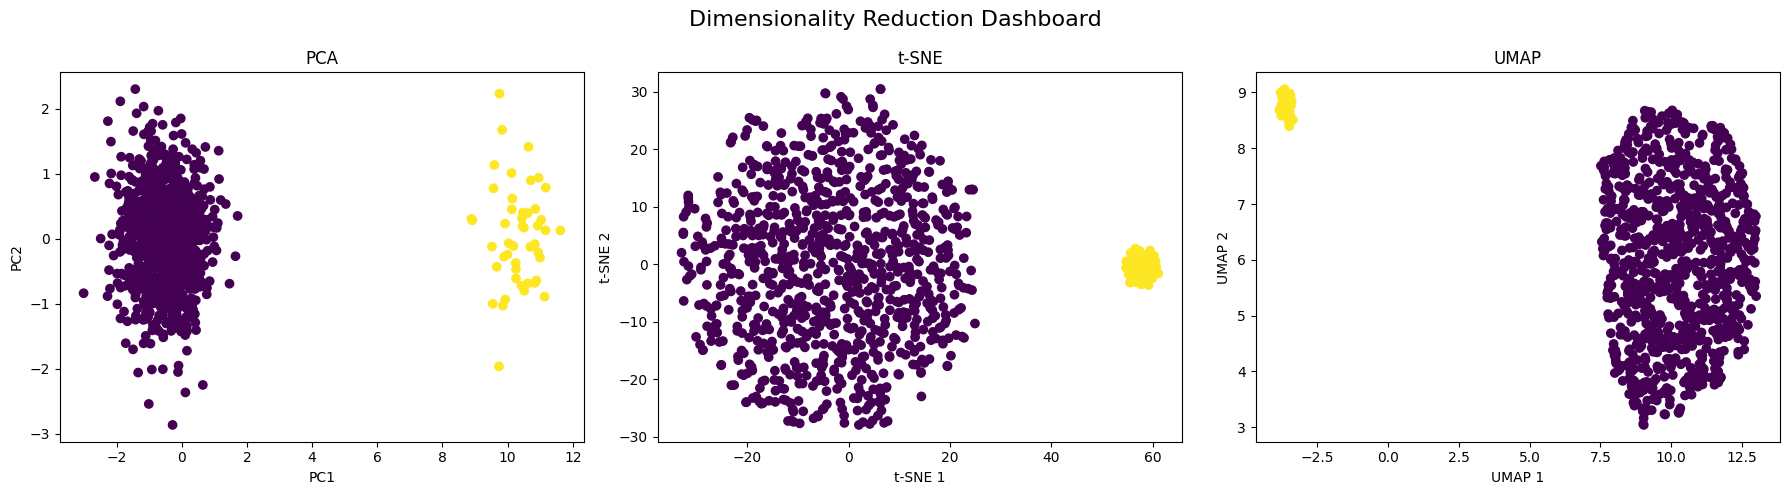


Dashboard saved as: dim_reduction_dashboard.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import umap


# ============================================================
# 3. CREATE DATASET
# ============================================================

np.random.seed(42)

# Normal data
normal_data = np.random.normal(
    loc=0,
    scale=1,
    size=(1000, 10)
)

# Anomaly data
anomaly_data = np.random.normal(
    loc=5,
    scale=1,
    size=(50, 10)
)

# Combine data
X = np.vstack([
    normal_data,
    anomaly_data
])

# Ground truth:
# 0 = Normal
# 1 = Anomaly
y_labels = np.concatenate([
    np.zeros(1000),
    np.ones(50)
])

# Create DataFrame
feature_names = [
    f"Feature_{i}"
    for i in range(1, 11)
]

df = pd.DataFrame(
    X,
    columns=feature_names
)

df["IsAnomaly"] = y_labels.astype(int)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())


# ============================================================
# 4. SCALE DATA
# ============================================================

X_features = df[feature_names]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_features
)

print("\nScaled data shape:", X_scaled.shape)


# ============================================================
# 5. PCA SCREE PLOT
# ============================================================

pca_full = PCA()

X_pca_full = pca_full.fit_transform(
    X_scaled
)

explained_variance = (
    pca_full.explained_variance_ratio_
)

cumulative_variance = np.cumsum(
    explained_variance
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.title(
    "PCA Scree Plot"
)

plt.grid(True)

plt.show()


# ============================================================
# 6. PCA CUMULATIVE VARIANCE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title(
    "PCA Cumulative Explained Variance"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% Variance"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 7. PCA 2D
# ============================================================

pca_2d = PCA(
    n_components=2
)

X_pca_2d = pca_2d.fit_transform(
    X_scaled
)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=y_labels
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA - 2D Visualization"
)

plt.grid(True)

plt.show()


# ============================================================
# 8. PCA 3D
# ============================================================

pca_3d = PCA(
    n_components=3
)

X_pca_3d = pca_3d.fit_transform(
    X_scaled
)

fig = plt.figure(
    figsize=(10, 7)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    c=y_labels
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

ax.set_title(
    "PCA - 3D Visualization"
)

plt.show()


# ============================================================
# 9. t-SNE PERPLEXITY SWEEP
# ============================================================

# Use a smaller sample for faster execution
sample_size = min(
    500,
    len(X_scaled)
)

sample_indices = np.random.choice(
    len(X_scaled),
    sample_size,
    replace=False
)

X_sample = X_scaled[
    sample_indices
]

y_sample = y_labels[
    sample_indices
]

perplexities = [
    5,
    10,
    20,
    30,
    40
]

tsne_results = {}

for perplexity in perplexities:

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    X_tsne = tsne.fit_transform(
        X_sample
    )

    tsne_results[
        perplexity
    ] = X_tsne


# Plot t-SNE results

fig, axes = plt.subplots(
    1,
    len(perplexities),
    figsize=(20, 4)
)

for i, perplexity in enumerate(
    perplexities
):

    axes[i].scatter(
        tsne_results[perplexity][:, 0],
        tsne_results[perplexity][:, 1],
        c=y_sample
    )

    axes[i].set_title(
        f"Perplexity = {perplexity}"
    )

    axes[i].set_xlabel("t-SNE 1")
    axes[i].set_ylabel("t-SNE 2")

plt.tight_layout()

plt.show()


# ============================================================
# 10. UMAP HYPERPARAMETER GRID
# ============================================================

n_neighbors_values = [
    5,
    15,
    30
]

min_dist_values = [
    0.1,
    0.5,
    0.9
]

fig, axes = plt.subplots(
    len(n_neighbors_values),
    len(min_dist_values),
    figsize=(15, 12)
)

for i, n_neighbors in enumerate(
    n_neighbors_values
):

    for j, min_dist in enumerate(
        min_dist_values
    ):

        reducer = umap.UMAP(
            n_components=2,
            n_neighbors=n_neighbors,
            min_dist=min_dist,
            random_state=42
        )

        X_umap = reducer.fit_transform(
            X_sample
        )

        axes[i, j].scatter(
            X_umap[:, 0],
            X_umap[:, 1],
            c=y_sample
        )

        axes[i, j].set_title(
            f"Neighbors={n_neighbors}, "
            f"MinDist={min_dist}"
        )

        axes[i, j].set_xlabel(
            "UMAP 1"
        )

        axes[i, j].set_ylabel(
            "UMAP 2"
        )

plt.tight_layout()

plt.show()


# ============================================================
# 11. ISOLATION FOREST
# ============================================================

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=50 / 1050,
    random_state=42
)

isolation_forest.fit(
    X_scaled
)

# Isolation Forest output:
# 1  = Normal
# -1 = Anomaly

if_predictions = isolation_forest.predict(
    X_scaled
)

# Convert to:
# 0 = Normal
# 1 = Anomaly

if_anomaly_labels = np.where(
    if_predictions == -1,
    1,
    0
)


# ============================================================
# 12. ISOLATION FOREST VS GROUND TRUTH
# ============================================================

print("\n================================================")
print("ISOLATION FOREST VS GROUND TRUTH")
print("================================================")

print(
    "\nAccuracy:",
    accuracy_score(
        y_labels,
        if_anomaly_labels
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_labels,
        if_anomaly_labels
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_labels,
        if_anomaly_labels,
        target_names=[
            "Normal",
            "Anomaly"
        ]
    )
)


# ============================================================
# 13. COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame({
    "GroundTruth_IsAnomaly": y_labels.astype(int),
    "IsolationForest_IsAnomaly": if_anomaly_labels
})

print("\nComparison Table:")
print(comparison.head(20))


# ============================================================
# 14. ISOLATION FOREST VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=if_anomaly_labels
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "Isolation Forest Anomaly Detection"
)

plt.grid(True)

plt.show()


# ============================================================
# 15. DIMENSION REDUCTION DASHBOARD FUNCTION
# ============================================================

def dim_reduction_dashboard(
    X_scaled,
    y_labels,
    sample_n=1000
):

    # --------------------------------------------------------
    # Select sample
    # --------------------------------------------------------

    n = min(
        sample_n,
        len(X_scaled)
    )

    np.random.seed(42)

    indices = np.random.choice(
        len(X_scaled),
        n,
        replace=False
    )

    X_sample = X_scaled[
        indices
    ]

    y_sample = y_labels[
        indices
    ]


    # --------------------------------------------------------
    # PCA
    # --------------------------------------------------------

    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(
        X_sample
    )


    # --------------------------------------------------------
    # t-SNE
    # --------------------------------------------------------

    # Perplexity must be smaller
    # than number of samples

    perplexity = min(
        30,
        max(5, (n - 1) // 3)
    )

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    X_tsne = tsne.fit_transform(
        X_sample
    )


    # --------------------------------------------------------
    # UMAP
    # --------------------------------------------------------

    n_neighbors = min(
        15,
        n - 1
    )

    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=0.1,
        random_state=42
    )

    X_umap = reducer.fit_transform(
        X_sample
    )


    # --------------------------------------------------------
    # Create 3-panel dashboard
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5)
    )


    # --------------------------------------------------------
    # PCA panel
    # --------------------------------------------------------

    axes[0].scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=y_sample
    )

    axes[0].set_title(
        "PCA"
    )

    axes[0].set_xlabel(
        "PC1"
    )

    axes[0].set_ylabel(
        "PC2"
    )


    # --------------------------------------------------------
    # t-SNE panel
    # --------------------------------------------------------

    axes[1].scatter(
        X_tsne[:, 0],
        X_tsne[:, 1],
        c=y_sample
    )

    axes[1].set_title(
        "t-SNE"
    )

    axes[1].set_xlabel(
        "t-SNE 1"
    )

    axes[1].set_ylabel(
        "t-SNE 2"
    )


    # --------------------------------------------------------
    # UMAP panel
    # --------------------------------------------------------

    axes[2].scatter(
        X_umap[:, 0],
        X_umap[:, 1],
        c=y_sample
    )

    axes[2].set_title(
        "UMAP"
    )

    axes[2].set_xlabel(
        "UMAP 1"
    )

    axes[2].set_ylabel(
        "UMAP 2"
    )


    # --------------------------------------------------------
    # Overall title
    # --------------------------------------------------------

    fig.suptitle(
        "Dimensionality Reduction Dashboard",
        fontsize=16
    )

    plt.tight_layout()


    # --------------------------------------------------------
    # Save as PNG
    # --------------------------------------------------------

    plt.savefig(
        "dim_reduction_dashboard.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "\nDashboard saved as: "
        "dim_reduction_dashboard.png"
    )


# ============================================================
# 16. RUN DIMENSION REDUCTION DASHBOARD
# ============================================================

dim_reduction_dashboard(
    X_scaled,
    y_labels,
    sample_n=1000
)